In [24]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

Analysis of RTC+B implementation on ERCOT.

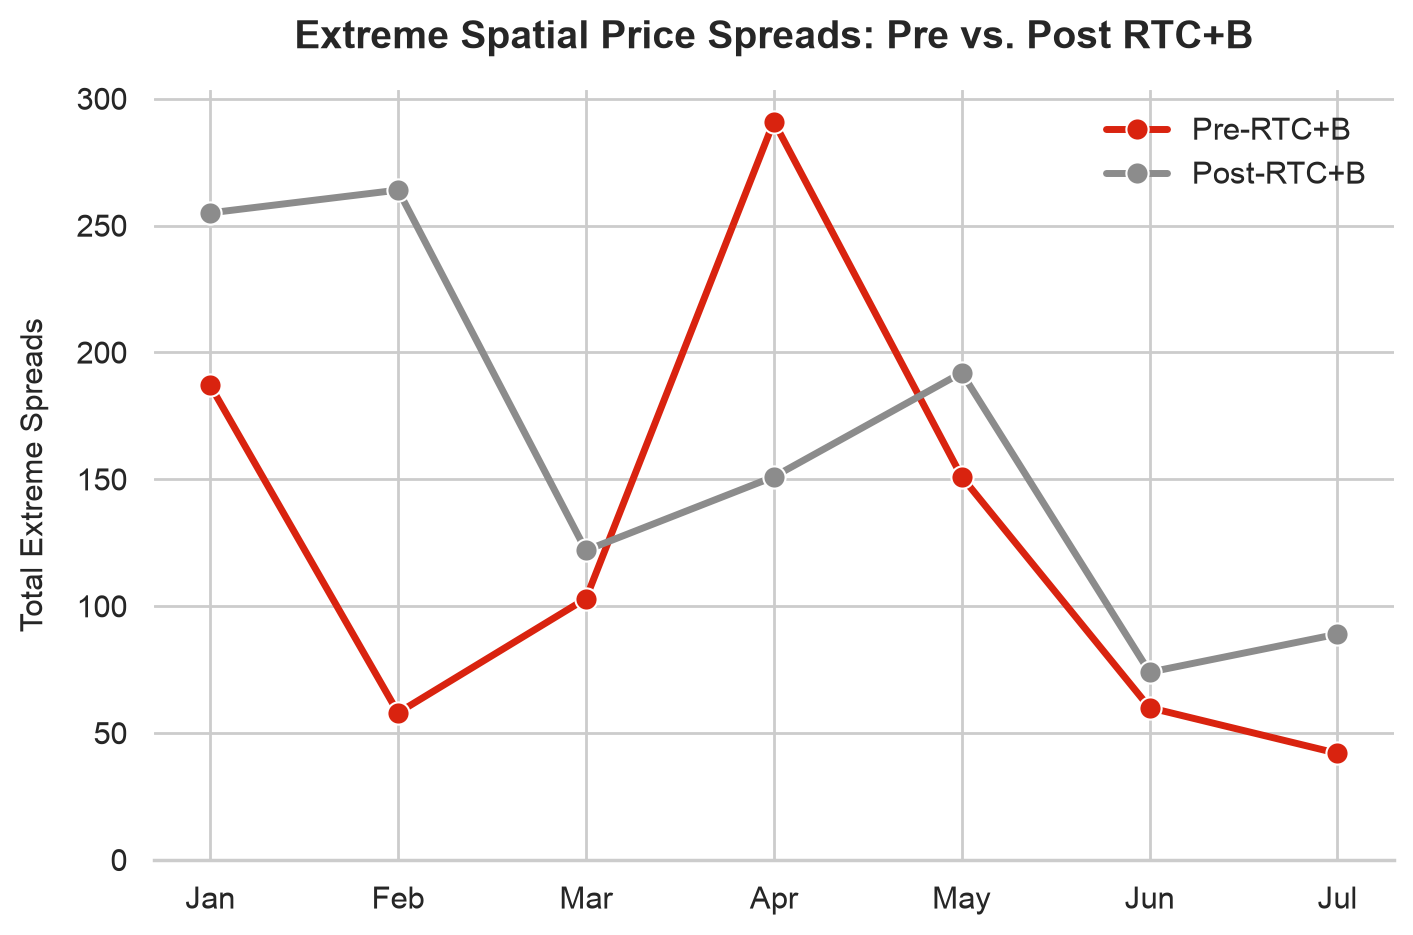

In [25]:
# Figure 1: Monthly amounts of “unusually” large spatial price spreads before and after RTC+B (Owen)

df = pd.read_csv("../data/ercot_artifex.csv")
df["time_utc"] = pd.to_datetime(df["datetime_utc"], format = "%m/%d/%y %H:%M")


fig1 = (
df.query("type == 'LZ'")
.groupby("time_utc", as_index=False)
.agg(max_spread = ("price", lambda x: x.max()-x.min()))
.assign(prepost = lambda x: np.where(x["time_utc"] < pd.Timestamp("2025-12-10"), "pre", "post" ),
       extreme = lambda x:  x["max_spread"] > x.loc[x["prepost"] == "pre", "max_spread"].quantile(.95),
       month = lambda x: x["time_utc"].dt.month)
.groupby(["month", "prepost"], as_index= False)
.agg(sum_extreme = ("extreme", "sum"))
.query("month <= 7")
)

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))
ax = sns.lineplot(
    data = fig1,
    x = "month",
    y = "sum_extreme",
    hue = "prepost",
    palette={"pre": "#8c8c8c", "post": "#d9230f"},
    marker="o",
    linewidth=2.5,
    markersize=8
)

ax.set_xticks(range(1, 8))
ax.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul'])
ax.set_ylim(bottom=0)

ax.set_title("Extreme Spatial Price Spreads: Pre vs. Post RTC+B", pad=15, fontsize=14, fontweight="bold")
ax.set_xlabel(None)  # "Month" is implied by the tick labels
ax.set_ylabel("Total Extreme Spreads", fontsize=11, labelpad=10)

handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Pre-RTC+B", "Post-RTC+B"], title=None, frameon=False)
sns.despine(left=True)
plt.show()

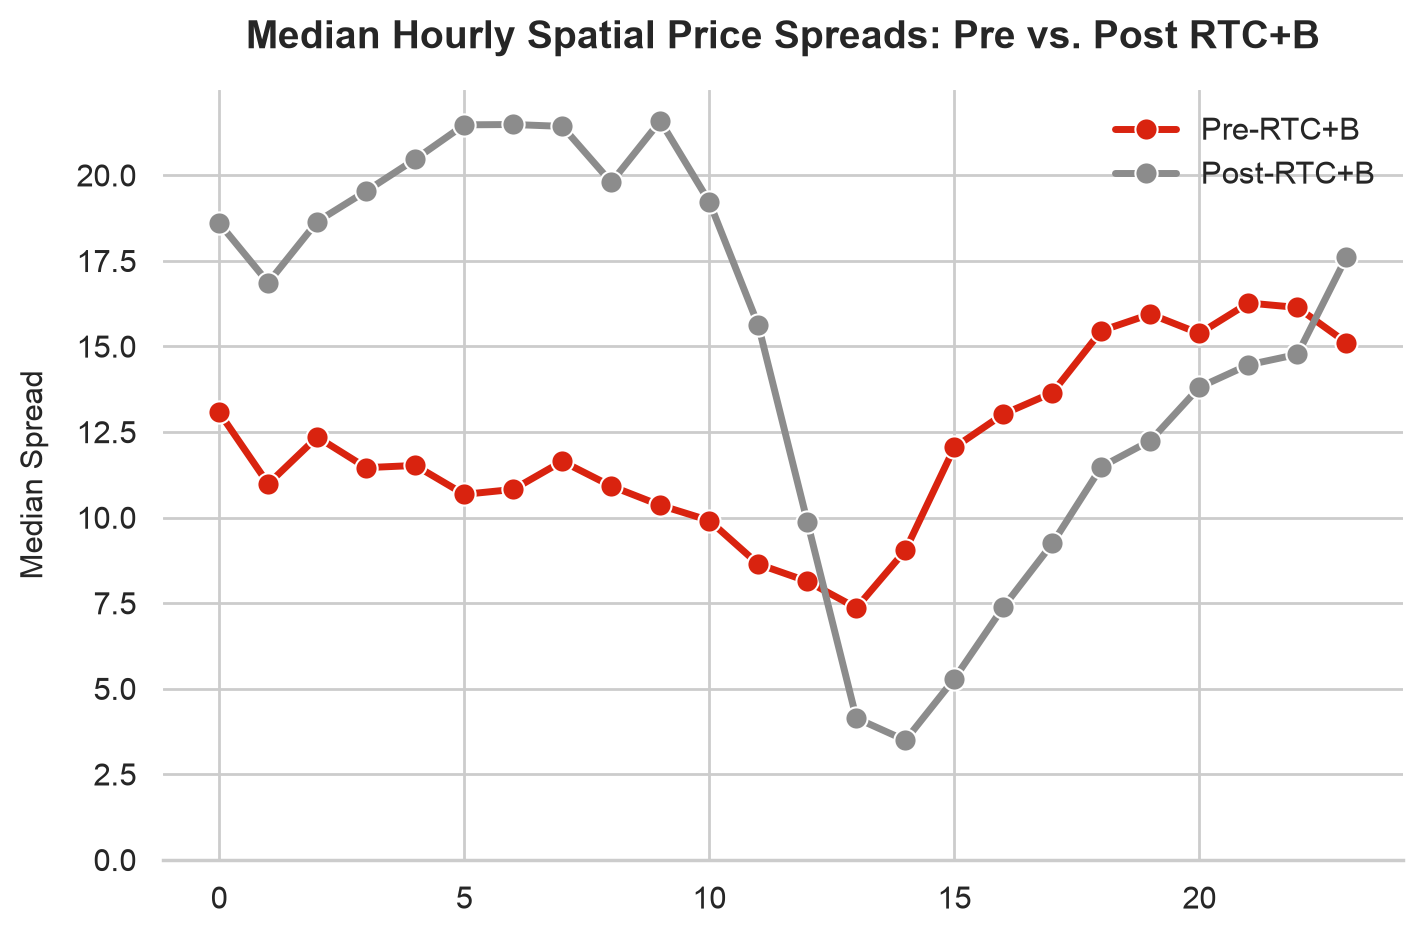

In [26]:
fig2 = (
df.query("type == 'LZ'")
.groupby("time_utc", as_index= False)
.agg(maxspread = ("price", lambda x: x.max() - x.min()))
.assign(prepost = lambda x: np.where(x["time_utc"] < pd.Timestamp("2025-12-10"), "pre", "post" ),
        hour = lambda x: x["time_utc"].dt.hour )
.groupby(["prepost", "hour"], as_index= False)
.agg(med_spread = ("maxspread", "median"))
)

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))
ax = sns.lineplot(
    data = fig2,
    x = "hour",
    y = "med_spread",
    hue = "prepost",
    palette={"pre": "#8c8c8c", "post": "#d9230f"},
    marker="o",
    linewidth=2.5,
    markersize=8
)

ax.set_ylim(bottom=0)
ax.set_title("Median Hourly Spatial Price Spreads: Pre vs. Post RTC+B", pad=15, fontsize=14, fontweight="bold")
ax.set_xlabel(None)  # "Month" is implied by the tick labels
ax.set_ylabel("Median Spread", fontsize=11, labelpad=10)

handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Pre-RTC+B", "Post-RTC+B"], title=None, frameon=False)
sns.despine(left=True)
plt.show()



Text(0.5, 1.0, 'Spread Compared with the Western Load Zone')

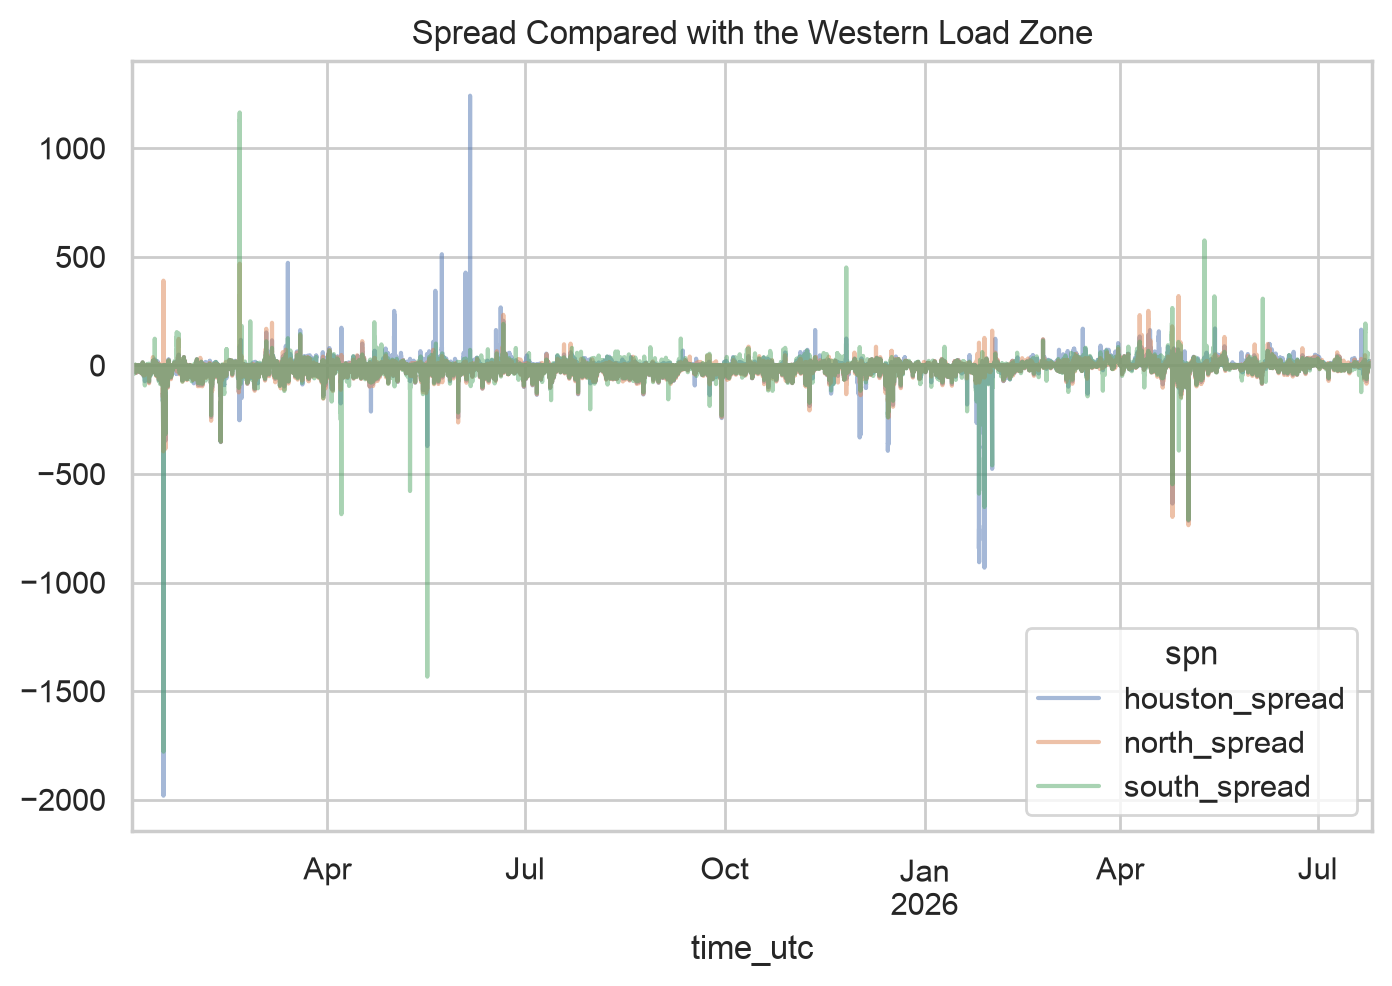

In [34]:
# spread by spn

fig3 = (
df.query("type == 'LZ'")
.pivot(index = 'time_utc', columns = 'spn', values = 'price')
.reset_index()
.assign(
    houston_spread = lambda x: x["LZ_HOUSTON"] - x["LZ_WEST"],
    north_spread = lambda x: x["LZ_NORTH"] - x["LZ_WEST"],
    south_spread = lambda x: x["LZ_SOUTH"] - x["LZ_WEST"],
))[['time_utc', 'houston_spread', 'north_spread', 'south_spread']]

# set 'time_utc' as the index
fig3.set_index('time_utc', inplace=True)

# # 3. Plot the specific columns together
fig3[['houston_spread', 'north_spread', 'south_spread']].plot(figsize=(8, 5), alpha = 0.5)

# # Add labels and show the plot
plt.title('Spread Compared with the Western Load Zone')
# plt.ylabel('LZ - LZ_WEST')
# plt.grid(True)